In [ ]:
import numpy as np
import pandas as pd
from sklearn.metrics import accuracy_score, precision_score, recall_score


In [ ]:
real_train = pd.read_csv(r'.../Train/SGA_train.csv')
#real_df = real_train.drop(columns=['Unnamed: 0'], axis=1)

In [ ]:
real_test= pd.read_csv(r'.../Test/SGA_test.csv')
#real_test

In [ ]:
syn = pd.read_csv(r'.../SGA_smote/Synthetic.csv')
syn_df = syn.drop(columns=['Unnamed: 0'], axis=1)

In [ ]:
# -------------------------------------------------------
# 0. Build attacker dataset (real_df + real_test)
# -------------------------------------------------------
# real_df   : real train (members)
# real_test : real test (non-members)
# syn_df    : synthetic data

attacker_train = real_train.copy()
attacker_train["is_member"] = 1  # real train -> member

attacker_test = real_test.copy()
attacker_test["is_member"] = 0   # real test -> non-member

# Attacker's view: mix of members + non-members
attacker_df = pd.concat([attacker_train, attacker_test], axis=0, ignore_index=True)

# Synthetic data (public)
synthetic_df = syn_df.copy()

In [ ]:
# -------------------------------------------------------
# 1. Distance function: Hamming distance
# -------------------------------------------------------
def hamming_distances_to_synthetic(row: pd.Series,
                                   synthetic_df: pd.DataFrame,
                                   cols=None) -> np.ndarray:
    """
    Compute Hamming distances between ONE real row and ALL synthetic rows.
    Hamming distance = (# mismatching features) / (# features).
    """
    if cols is None:
        cols = synthetic_df.columns

    # One real row -> 1D array
    r = row[cols].to_numpy()
    # All synthetic rows -> 2D array
    S = synthetic_df[cols].to_numpy()

    # Boolean matrix: True where values differ
    mismatches = (S != r)

    # Count mismatches per synthetic row, normalize by number of features
    dists = mismatches.sum(axis=1) / float(len(cols))
    return dists


In [ ]:
# -------------------------------------------------------
# 2. Membership Inference Attack (Algorithm 1)
# -------------------------------------------------------
def simulate_mia(attacker_df: pd.DataFrame,
                 synthetic_df: pd.DataFrame,
                 thr: float = 0.2,
                 member_col: str = "is_member") -> pd.Series:
    """
    For each row in attacker_df:
        dists = distances to all synthetic rows
        if min(dists) < thr -> identified as member (True)
        else -> non-member (False)

    Returns a boolean Series (attack prediction for each real record).
    """
    # Use only common feature columns, drop membership label
    cols = attacker_df.columns.intersection(synthetic_df.columns)
    if member_col in cols:
        cols = cols.drop(member_col)

    identified_flags = []

    for _, row in attacker_df.iterrows():
        dists = hamming_distances_to_synthetic(row, synthetic_df, cols=cols)
        record_identified = (dists.min() < thr)
        identified_flags.append(record_identified)

    return pd.Series(
        identified_flags,
        index=attacker_df.index,
        name=f"identified_thr_{thr}"
    )


In [ ]:
# -------------------------------------------------------
# 3. Run attack for multiple thresholds
# -------------------------------------------------------
thresholds = [0.7, 0.6, 0.5, 0.4, 0.3, 0.2, 0.1]
mia_results = {}

for thr in thresholds:
    identified = simulate_mia(attacker_df, synthetic_df, thr=thr, member_col="is_member")
    attacker_df[f"identified_thr_{thr}"] = identified.astype(int)
    mia_results[thr] = identified

    # Fraction of real records flagged as "member" by the attack
    frac_identified = identified.mean()
    print(f"thr = {thr:.2f} | fraction identified = {frac_identified:.3f}")


In [ ]:
# -------------------------------------------------------
# 4. OPTIONAL: Evaluate attack performance (needs is_member ground truth)
# -------------------------------------------------------
def evaluate_mia(attacker_df: pd.DataFrame,
                 identified: pd.Series,
                 member_col: str = "is_member"):
    y_true = attacker_df[member_col].astype(int).to_numpy()
    y_pred = identified.astype(int).to_numpy()

    acc = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred, zero_division=0)
    rec = recall_score(y_true, y_pred, zero_division=0)

    return {"accuracy": acc, "precision": prec, "recall": rec}

for thr in thresholds:
    metrics = evaluate_mia(attacker_df, mia_results[thr], member_col="is_member")
    print(f"thr = {thr:.2f} | {metrics}")

In [ ]:
# Compute false positive rate

In [ ]:
def compute_tpr_fpr(attacker_df, identified, member_col="is_member"):
    df = attacker_df.copy()
    df["y_true"] = df[member_col].astype(int)
    df["y_pred"] = identified.astype(int)

    # True members (real_df)
    members = df[df["y_true"] == 1]
    # True non-members (real_test)
    non_members = df[df["y_true"] == 0]

    # TPR = recall on members
    tpr = (members["y_pred"] == 1).mean()
    # FPR = how many non-members are wrongly called members
    fpr = (non_members["y_pred"] == 1).mean()

    return tpr, fpr

for thr in thresholds:
    identified = mia_results[thr]
    tpr, fpr = compute_tpr_fpr(attacker_df, identified, member_col="is_member")
    print(f"thr={thr:.2f} | TPR={tpr:.3f}, FPR={fpr:.3f}")

In [ ]:
# Plot

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# -------------------------------
# Your MIA data
# -------------------------------
thresholds = np.array([0.40, 0.30, 0.20, 0.10])
TPR = np.array([1.000, 0.999, 0.842, 0.116])
FPR = np.array([1.000, 0.998, 0.799, 0.082])

# -------------------------------
# Create plot
# -------------------------------
plt.figure(figsize=(6, 6))

# ROC curve
plt.plot(FPR, TPR, marker='o', linewidth=2)

# Random baseline
plt.plot([0, 1], [0, 1], linestyle='--')

# ✅ Offsets designed to KEEP labels inside the plot box
label_offsets = {
    0.40: (-0.25, -0.04),   # inside, left-down
    0.30: (-0.25, -0.08),   # inside, more left-down
    0.20: ( 0.03, -0.07),   # inside, right-down
    0.10: ( 0.03,  -0.07),   # inside, right-up
}

# Add short, clean arrows
for i, thr in enumerate(thresholds):
    dx, dy = label_offsets[thr]
    plt.annotate(
        f"thr={thr:.2f}",
        xy=(FPR[i], TPR[i]),
        xytext=(FPR[i] + dx, TPR[i] + dy),
        arrowprops=dict(arrowstyle="->", lw=0.8),
        fontsize=10
    )

# Labels & styling
plt.xlabel("False Positive Rate (FPR)")
plt.ylabel("True Positive Rate (TPR)")
#plt.title("Membership Inference Attack (MIA) Performance")

plt.xlim(0, 1)
plt.ylim(0, 1)
plt.grid(True)

# Save high-resolution versions
#plt.savefig("mia_tpr_fpr_curve_inside_labels.png", dpi=600, bbox_inches="tight")
# plt.savefig("mia_tpr_fpr_curve_inside_labels.pdf", dpi=600, bbox_inches="tight")

plt.show()

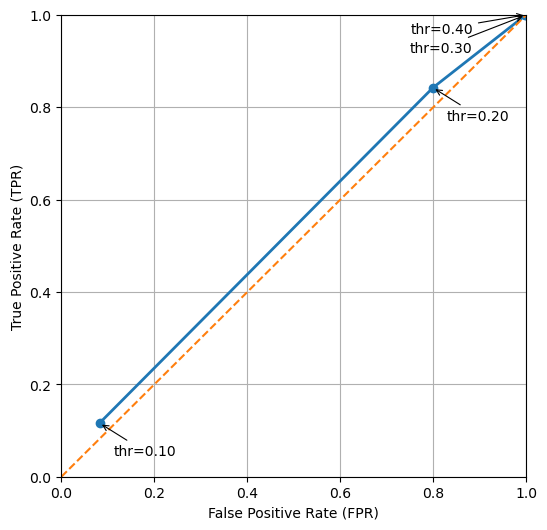